HOUSE PRICE DATASET
   Area  Bedrooms  Bathrooms  Age  Floors  Parking  Location_Score  \
0  3674         2          1   22       2        1               9   
1  1360         1          2   23       1        1               4   
2  1794         2          1   12       2        0               9   
3  1630         1          1   21       2        0               4   
4  1595         4          2   36       3        2               2   

          Price  
0  1.223446e+07  
1  4.896558e+06  
2  7.748383e+06  
3  6.065644e+06  
4  7.071806e+06  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Area            1000 non-null   int64  
 1   Bedrooms        1000 non-null   int64  
 2   Bathrooms       1000 non-null   int64  
 3   Age             1000 non-null   int64  
 4   Floors          1000 non-null   int64  
 5   Park

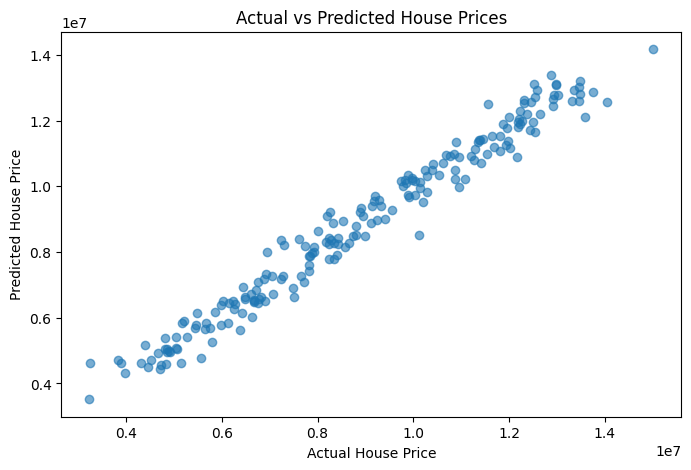


NEW HOUSE DETAILS
   Area  Bedrooms  Bathrooms  Age  Floors  Parking  Location_Score
0  1500         3          2    5       2        1               8

Predicted House Price: Rs. 7022954.08


In [4]:

# HOUSE PRICE PREDICTION USING RANDOM FOREST REGRESSION

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Step 2: Generate a sample house dataset
np.random.seed(42)

n = 1000

data = pd.DataFrame({
    'Area': np.random.randint(500, 4000, n),
    'Bedrooms': np.random.randint(1, 6, n),
    'Bathrooms': np.random.randint(1, 5, n),
    'Age': np.random.randint(0, 40, n),
    'Floors': np.random.randint(1, 4, n),
    'Parking': np.random.randint(0, 3, n),
    'Location_Score': np.random.randint(1, 11, n)
})

# Step 3: Generate sample house prices
data['Price'] = (
    500000
    + data['Area'] * 2500
    + data['Bedrooms'] * 300000
    + data['Bathrooms'] * 200000
    - data['Age'] * 15000
    + data['Floors'] * 100000
    + data['Parking'] * 150000
    + data['Location_Score'] * 200000
    + np.random.normal(0, 300000, n)
)

data['Price'] = data['Price'].clip(lower=500000)

# Step 4: Display the dataset
print("HOUSE PRICE DATASET")
print(data.head())

# Step 5: Check dataset information
print("\nDataset Information:")
print(data.info())

# Step 6: Separate input and output variables
X = data.drop('Price', axis=1)
y = data['Price']

# Step 7: Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Step 8: Create Random Forest Regression model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Step 9: Train the model
model.fit(X_train, y_train)

print("\nModel Training Completed Successfully!")

# Step 10: Predict house prices
y_pred = model.predict(X_test)

print("\nPredicted House Prices:")
print(y_pred[:10])

print("\nActual House Prices:")
print(y_test.iloc[:10].values)

# Step 11: Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

# Step 12: Visualize actual and predicted prices
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

# Step 13: Predict the price of a new house
new_house = pd.DataFrame([{
    'Area': 1500,
    'Bedrooms': 3,
    'Bathrooms': 2,
    'Age': 5,
    'Floors': 2,
    'Parking': 1,
    'Location_Score': 8
}])

predicted_price = model.predict(new_house)

print("\nNEW HOUSE DETAILS")
print(new_house)

print("\nPredicted House Price: Rs.",
      round(predicted_price[0], 2))
